In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv")


engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64


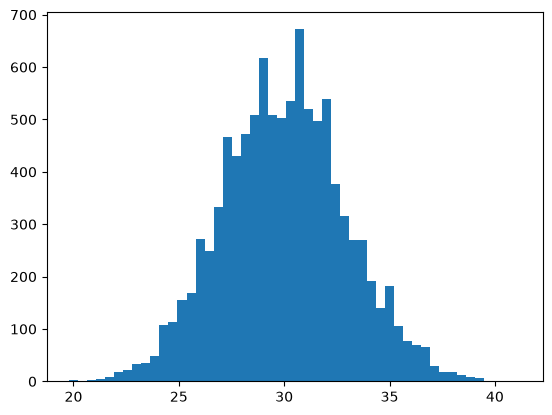

count    9123.000000
mean      254.446016
std        22.844613
min       171.000000
25%       239.000000
50%       254.000000
75%       270.000000
max       334.000000
Name: horsepower, dtype: float64


In [11]:

y = df["fuel_efficiency_mpg"]
features = ['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']
df_filtered = df[features]
print(df_filtered.isnull().sum())

plt.hist(y, bins = 50)
plt.show()

print(df_filtered["horsepower"].describe())

In [66]:
n = df_filtered.shape[0]
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_filtered.iloc[idx[:n_train]]
df_val = df_filtered.iloc[idx[n_train:n_train + n_val]]
df_test = df_filtered.iloc[idx[n_train + n_val:]]

df_train.reset_index(drop=True, inplace=True)
df_val.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

y_train = df_train["fuel_efficiency_mpg"]
y_val = df_val["fuel_efficiency_mpg"]
y_test = df_test["fuel_efficiency_mpg"]

del df_train["fuel_efficiency_mpg"]
del df_val["fuel_efficiency_mpg"]
del df_test["fuel_efficiency_mpg"]

In [37]:
print(df_val)

      engine_displacement  horsepower  vehicle_weight  model_year
0                    2240       265.0            3990        2004
1                    2390       259.0            4770        2019
2                    2360       265.0            4320        2018
3                    2430       279.0            4430        2008
4                    2220       249.0            4030        1999
...                   ...         ...             ...         ...
1995                 1980       229.0            4140        2020
1996                 2590       263.0            4630        1989
1997                 2390       264.0            4550        2017
1998                 2330       244.0            4440        2014
1999                 2170       260.0            4460        2021

[2000 rows x 4 columns]


In [67]:
def prepare_X_zeros(df):
    df = df.copy()
    df = df.fillna(0)
    X = df.values
    return X

def prepare_X_mean(df):
    df = df.copy()
    df["horsepower"] = df["horsepower"].fillna(df_train["horsepower"].mean())
    X = df.values
    return X


def train_linear_regression(X, y):
    ones = np.ones(len(X))
    X = np.column_stack([ones, X])
    XTX = np.transpose(X).dot(X)
    weights = np.linalg.inv(XTX).dot(np.transpose(X)).dot(y)
    return weights[0], weights[1:]

def rmse(pred, actual):
    residuals = (actual - pred) ** 2
    return np.sqrt(residuals.sum()/len(residuals))


In [70]:
X_zero = prepare_X_zeros(df_train)
X_mean = prepare_X_mean(df_train)



w0_zero, w_zero = train_linear_regression(X_zero, y_train)
w0_mean, w_mean = train_linear_regression(X_mean, y_train)


X_val_zero = prepare_X_zeros(df_val)
X_val_mean = prepare_X_mean(df_val)



score_zero = rmse(w0_zero + X_val_zero.dot(w_zero), y_val)
score_mean = rmse(w0_mean + X_val_mean.dot(w_mean), y_val)

print(round(score_zero, 3))
print(round(score_mean, 3))


2.205
2.202


In [73]:
def train_linear_regression_regularization(X, y, p):
    ones = np.ones(len(X))
    X = np.column_stack([ones, X])
    XTX = np.transpose(X).dot(X)
    XTX = XTX + p * np.eye(len(XTX))
    weights = np.linalg.inv(XTX).dot(np.transpose(X)).dot(y)
    return weights[0], weights[1:]

In [75]:
X_train = prepare_X_zeros(df_train)
X_val = prepare_X_zeros(df_val)

for p in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_regularization(X_train, y_train, p)
    print(p)
    print(round(rmse(w0 + X_val.dot(w), y_val),4))
    print("-------------")



0
2.2053
-------------
0.01
2.2058
-------------
0.1
2.2241
-------------
1
2.3492
-------------
5
2.4094
-------------
10
2.4195
-------------
100
2.4292
-------------


In [76]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores = []
n = df_filtered.shape[0]
for seed in seeds:
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df_filtered.iloc[idx[:n_train]]
    df_val = df_filtered.iloc[idx[n_train:n_train + n_val]]
    df_test = df_filtered.iloc[idx[n_train + n_val:]]

    df_train.reset_index(drop=True, inplace=True)
    df_val.reset_index(drop=True, inplace=True)
    df_test.reset_index(drop=True, inplace=True)

    y_train = df_train["fuel_efficiency_mpg"]
    y_val = df_val["fuel_efficiency_mpg"]
    y_test = df_test["fuel_efficiency_mpg"]

    del df_train["fuel_efficiency_mpg"]
    del df_val["fuel_efficiency_mpg"]
    del df_test["fuel_efficiency_mpg"]

    X_train = prepare_X_zeros(df_train)
    X_val = prepare_X_zeros(df_val)

    w0, w = train_linear_regression(X_train, y_train)
    scores.append(rmse(w0 + X_val.dot(w), y_val))

print(round(np.std(scores),3))

0.029


In [77]:
np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df_filtered.iloc[idx[:n_train]]
df_val = df_filtered.iloc[idx[n_train:n_train + n_val]]
df_test = df_filtered.iloc[idx[n_train + n_val:]]

df_train.reset_index(drop=True, inplace=True)
df_val.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

y_train = df_train["fuel_efficiency_mpg"]
y_val = df_val["fuel_efficiency_mpg"]
y_test = df_test["fuel_efficiency_mpg"]

del df_train["fuel_efficiency_mpg"]
del df_val["fuel_efficiency_mpg"]
del df_test["fuel_efficiency_mpg"]

df_full_train = pd.concat([df_train, df_val])
X_full = prepare_X_zeros(df_full_train)
y_full = np.concat((y_train, y_val))

w0, w = train_linear_regression_regularization(X_full, y_full, 0.001)
X_test = prepare_X_zeros(df_test)
score = rmse(w0 + X_test.dot(w), y_test)
print(score)

2.235827747191731
